### Open the Lock (Medium)
ou have a lock in front of you with 4 circular wheels. Each wheel has 10 slots: '0', '1', '2', '3', '4', '5', '6', '7', '8', '9'. The wheels can rotate freely and wrap around: for example we can turn '9' to be '0', or '0' to be '9'. Each move consists of turning one wheel one slot.

The lock initially starts at '0000', a string representing the state of the 4 wheels.

You are given a list of deadends dead ends, meaning if the lock displays any of these codes, the wheels of the lock will stop turning and you will be unable to open it.

Given a target representing the value of the wheels that will unlock the lock, return the minimum total number of turns required to open the lock, or -1 if it is impossible.

 

Example 1:

Input: deadends = ["0201","0101","0102","1212","2002"], target = "0202"
Output: 6
Explanation: 
A sequence of valid moves would be "0000" -> "1000" -> "1100" -> "1200" -> "1201" -> "1202" -> "0202".
Note that a sequence like "0000" -> "0001" -> "0002" -> "0102" -> "0202" would be invalid,
because the wheels of the lock become stuck after the display becomes the dead end "0102".
Example 2:

Input: deadends = ["8888"], target = "0009"
Output: 1
Explanation: We can turn the last wheel in reverse to move from "0000" -> "0009".
Example 3:

Input: deadends = ["8887","8889","8878","8898","8788","8988","7888","9888"], target = "8888"
Output: -1
Explanation: We cannot reach the target without getting stuck.
 

Constraints:

1 <= deadends.length <= 500
deadends[i].length == 4
target.length == 4
target will not be in the list deadends.
target and deadends[i] consist of digits only.

In [1]:
from collections import deque

In [ ]:
class Solution:
    def openLock(self, deadends: list[str], target: str) -> int:

        # our first situation is if the starting string is in the deadlock
        if '0000' in deadends:
            return -1
        # second case, if the starting string is the target
        if target == '0000':
            return 0
        # we have to get the next_digit of every string
        next_digits = {}
        for i in range(10):
            next_digits[str(i)] = str((i+1)%10)
        # we define a prev_digits dictionary similary
        prev_digits = {}
        for key, val in next_digits.items():
            prev_digits[val] = key
        deadlock = set(deadends)
        # we define a get neighbors function
        # for every combo, there will be eight neighbors provided none of them are in a deadlock
        def get_neighbors(combo:str) -> list[str]:
            neighbors = []
            # for every combo, we will iterate through every single digit
            for i in range(4):
                # next_digit neighbor wrt ith element in the combo
                next_digit_neighbor = combo[:i] + next_digits[combo[i]] + combo[i+1:]
                if next_digit_neighbor not in deadlock:
                    neighbors.append(next_digit_neighbor)
                prev_digit_neighbor = combo[:i] + prev_digits[combo[i]] + combo[i+1:]
                if prev_digit_neighbor not in deadlock:
                    neighbors.append(prev_digit_neighbor)

            return neighbors

        # we perform bfs on the combinations
        # we enqueue 0000 and add it to the visited set
        queue = deque(['0000'])
        visited = {'0000'}
        steps = 0 # we are at 0 steps initially
        while queue:
            n = len(queue)
            # for each level, we pop all the elements, and append its neighbors provided they are not in the visited already
            for _ in range(n):
                node = queue.popleft()
                # get all the neighbors of the node
                for neighbor in get_neighbors(node):
                    # check if any neighbor is the target
                    if neighbor == target:
                        return steps+1
                    # if neighbor is not in visited already, we append it to the queue and the visited set
                    if neighbor not in visited:
                        queue.append(neighbor)
                        visited.add(neighbor)
            #at the end of each level, we increment the number of steps taken
            steps += 1

        # if our bfs function does not return anything, we return -1 because we did not find the target
        return -1


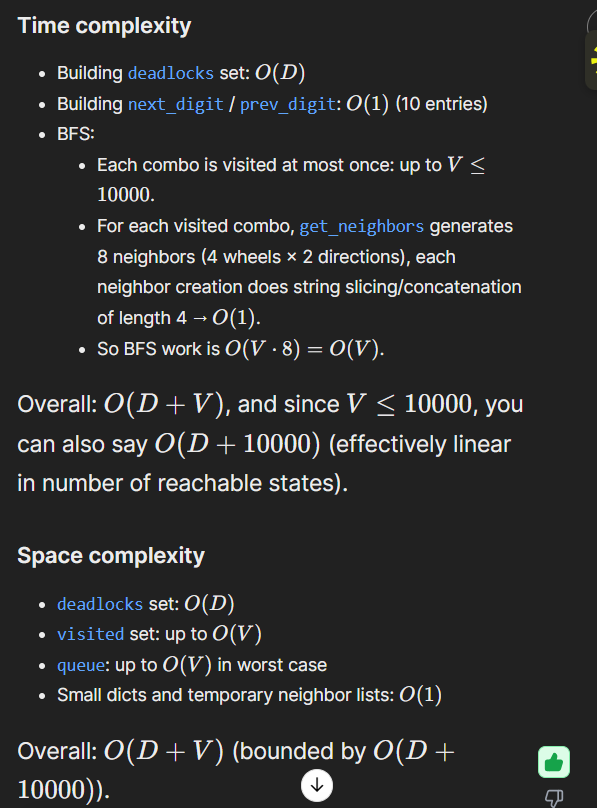